# GitHub Repository Contributor & Health Monitor: Exploratory Data Analysis (EDA)

## 1. Project Overview & Problem Statement
Thousands of open-source repositories exist on GitHub, but finding the right projects to contribute to or assessing their overall project health is challenging when looking only at raw numbers like stars. 

This analysis examines **300 public GitHub repositories** extracted via the GitHub REST API, validated with **Pydantic**, and loaded from our **SQLite database** (`data/processed/repositories.db`).

### Key Objectives:
- Investigate distributions of popularity, activity, and maintenance across 300 repositories.
- Compare programming languages and ecosystem traits.
- Formulate and analyze health and contributor-friendliness indicators across **27 metrics**.
- Identify active, healthy repositories ideal for new contributors, versus stagnant, abandoned repositories.

In [1]:
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Ingesting Processed Data from SQLite
We connect to our SQLite database (`data/processed/repositories.db`) and load the `repositories` table into a pandas DataFrame.

In [2]:
# Connect to SQLite and load data
db_path = Path("../data/processed/repositories.db")
if not db_path.exists():
    db_path = Path("data/processed/repositories.db")

conn = sqlite3.connect(db_path)
df = pd.read_sql_query("SELECT * FROM repositories", conn)
conn.close()

print(f"Dataset successfully loaded from SQLite database.")
print(f"Total Rows (Repositories): {df.shape[0]}")
print(f"Total Columns (Metrics & Metadata): {df.shape[1]}")
df.head(5)

Dataset successfully loaded from SQLite database.
Total Rows (Repositories): 300
Total Columns (Metrics & Metadata): 40


,repo_id,name,full_name,owner,html_url,description,language,category,license,default_branch,...,fork_to_star_ratio,issues_to_star_ratio,issues_to_fork_ratio,push_recency_score,documentation_score,community_health_score,maintenance_health_score,contributor_friendliness_score,activity_status,is_potentially_abandoned
0,45717250,tensorflow,tensorflow/tensorflow,tensorflow,https://github.com/tensorflow/tensorflow,An Open Source Machine Learning Framework for ...,C++,Artificial Intelligence & Machine Learning,Apache License 2.0,master,...,0.3912,0.0170,0.0435,100.0,75.0,75.00,87.73,72.50,Active,0
1,574523116,prompts.chat,f/prompts.chat,f,https://github.com/f/prompts.chat,"f.k.a. Awesome ChatGPT Prompts. Share, discove...",HTML,Artificial Intelligence & Machine Learning,Other,main,...,0.1276,0.0005,0.0035,100.0,65.0,64.14,84.05,89.41,Active,0
2,155220641,transformers,huggingface/transformers,huggingface,https://github.com/huggingface/transformers,🤗 Transformers: the model-definition framework...,Python,Artificial Intelligence & Machine Learning,Apache License 2.0,main,...,0.2081,0.0061,0.0292,100.0,100.0,75.00,94.63,80.04,Active,0
3,669879380,LLMs-from-scratch,rasbt/LLMs-from-scratch,rasbt,https://github.com/rasbt/LLMs-from-scratch,Implement a ChatGPT-like LLM in PyTorch from s...,Jupyter Notebook,Artificial Intelligence & Machine Learning,Other,main,...,0.1542,0.0000,0.0003,94.5,40.0,73.13,77.43,60.05,Active,0
4,65600975,pytorch,pytorch/pytorch,pytorch,https://github.com/pytorch/pytorch,Tensors and Dynamic neural networks in Python ...,Python,Artificial Intelligence & Machine Learning,Other,main,...,0.3029,0.1691,0.5583,100.0,65.0,75.00,76.10,70.50,Active,0


## 3. Data Integrity & Metric Inventory
Let's inspect the metrics present in our dataset. Our pipeline engineered and validated **27 distinct metrics** (17 raw extraction metrics + 10 derived health indicators).

In [3]:
raw_metrics = [
    'stars_count', 'forks_count', 'open_issues_count', 'watchers_count', 'size_kb',
    'repo_age_days', 'days_since_last_push', 'days_since_last_update',
    'has_issues_enabled', 'has_projects_enabled', 'has_wiki_enabled',
    'has_pages_enabled', 'has_discussions_enabled', 'has_license',
    'is_archived', 'topics_count', 'description_length'
]

derived_metrics = [
    'fork_to_star_ratio', 'issues_to_star_ratio', 'issues_to_fork_ratio',
    'push_recency_score', 'documentation_score', 'community_health_score',
    'maintenance_health_score', 'contributor_friendliness_score',
    'activity_status', 'is_potentially_abandoned'
]

print(f"Raw Metrics ({len(raw_metrics)}):", ", ".join(raw_metrics))
print()
print(f"Derived Metrics ({len(derived_metrics)}):", ", ".join(derived_metrics))
print()
print("Missing values per column:")
missing = df[raw_metrics + derived_metrics].isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Zero missing values across all metrics!")

Raw Metrics (17): stars_count, forks_count, open_issues_count, watchers_count, size_kb, repo_age_days, days_since_last_push, days_since_last_update, has_issues_enabled, has_projects_enabled, has_wiki_enabled, has_pages_enabled, has_discussions_enabled, has_license, is_archived, topics_count, description_length

Derived Metrics (10): fork_to_star_ratio, issues_to_star_ratio, issues_to_fork_ratio, push_recency_score, documentation_score, community_health_score, maintenance_health_score, contributor_friendliness_score, activity_status, is_potentially_abandoned

Missing values per column:
Zero missing values across all metrics!


## 4. Descriptive Statistics of Core Metrics
Let's examine the central tendencies, spread, percentiles, and skewness of the primary numerical features.

In [4]:
numeric_subset = [
    'stars_count', 'forks_count', 'open_issues_count', 'size_kb',
    'repo_age_days', 'days_since_last_push', 'maintenance_health_score',
    'contributor_friendliness_score'
]
df[numeric_subset].describe().round(2)

,stars_count,forks_count,open_issues_count,size_kb,repo_age_days,days_since_last_push,maintenance_health_score,contributor_friendliness_score
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,22677.31,4181.27,347.24,293963.85,2865.18,355.08,71.14,56.09
std,23855.10,6281.70,1157.03,612148.25,1126.09,547.94,25.73,40.15
min,7322.00,401.00,0.00,105.00,89.00,0.00,0.00,0.00
25%,9619.75,1368.00,21.00,14359.50,2190.98,1.75,52.80,0.00
50%,14932.50,2521.00,81.00,71850.00,2993.35,32.30,82.38,74.18
75%,24988.50,4415.50,315.50,271718.00,3529.27,729.70,90.40,89.95
max,201292.00,78739.00,17785.00,4768510.00,6298.60,2633.30,100.00,99.84


## 5. Repository Popularity & Distribution (Stars, Forks, Issues)
Open source repositories exhibit heavy long-tail (power-law) distributions in stars, forks, and issues. We visualize both raw and log-transformed distributions to reveal the true scale.

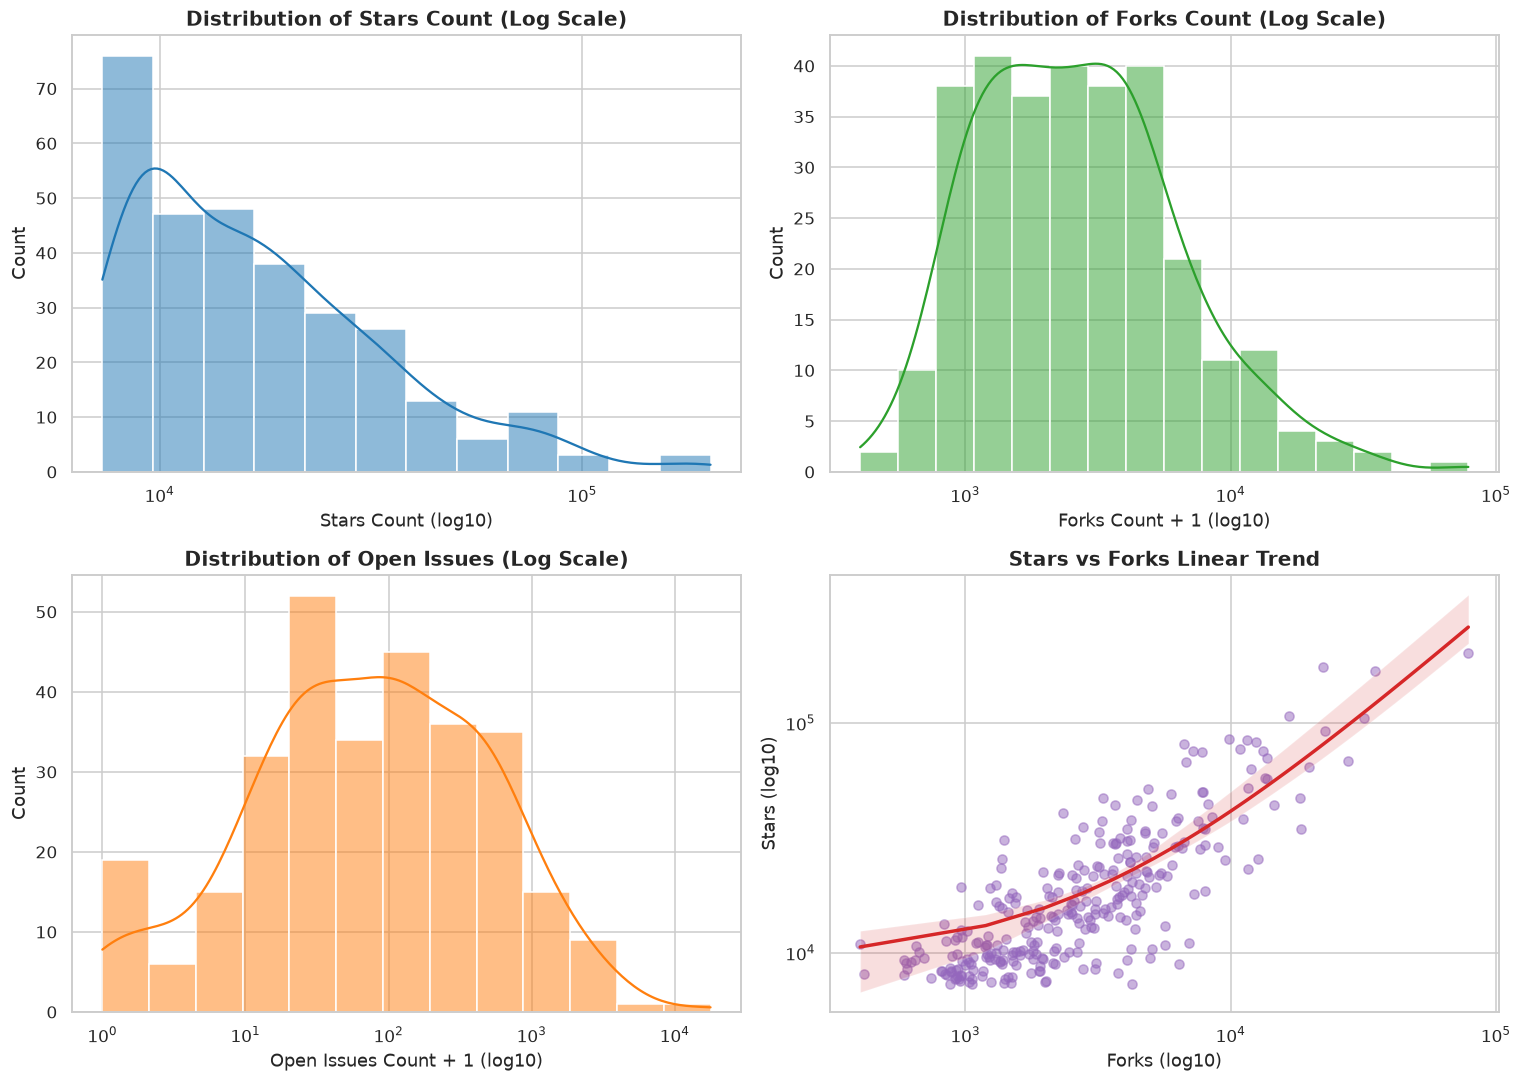

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Stars Distribution (Log Scale)
sns.histplot(df['stars_count'], kde=True, log_scale=True, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].set_title("Distribution of Stars Count (Log Scale)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Stars Count (log10)")

# 2. Forks Distribution (Log Scale)
sns.histplot(df['forks_count'] + 1, kde=True, log_scale=True, ax=axes[0, 1], color='#2ca02c')
axes[0, 1].set_title("Distribution of Forks Count (Log Scale)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Forks Count + 1 (log10)")

# 3. Open Issues Distribution (Log Scale)
sns.histplot(df['open_issues_count'] + 1, kde=True, log_scale=True, ax=axes[1, 0], color='#ff7f0e')
axes[1, 0].set_title("Distribution of Open Issues (Log Scale)", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Open Issues Count + 1 (log10)")

# 4. Stars vs Forks Scatter Plot with regression
sns.regplot(data=df, x='forks_count', y='stars_count', ax=axes[1, 1],
            scatter_kws={'alpha': 0.5, 'color': '#9467bd'}, line_kws={'color': '#d62728'})
axes[1, 1].set_title("Stars vs Forks Linear Trend", fontsize=13, fontweight='bold')
axes[1, 1].set_xscale('log')
axes[1, 1].set_yscale('log')
axes[1, 1].set_xlabel("Forks (log10)")
axes[1, 1].set_ylabel("Stars (log10)")

plt.tight_layout()
plt.show()

## 6. Language Landscape & Ecosystem Breakdown
Which programming languages dominate the repositories, and how do their median stars and maintenance health scores compare?

/tmp/ipykernel_8384/3461094742.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_top_lang, y='language', order=top_languages, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_8384/3461094742.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_lang, x='maintenance_health_score', y='language', order=top_languages, ax=axes[1], palette='Set2')


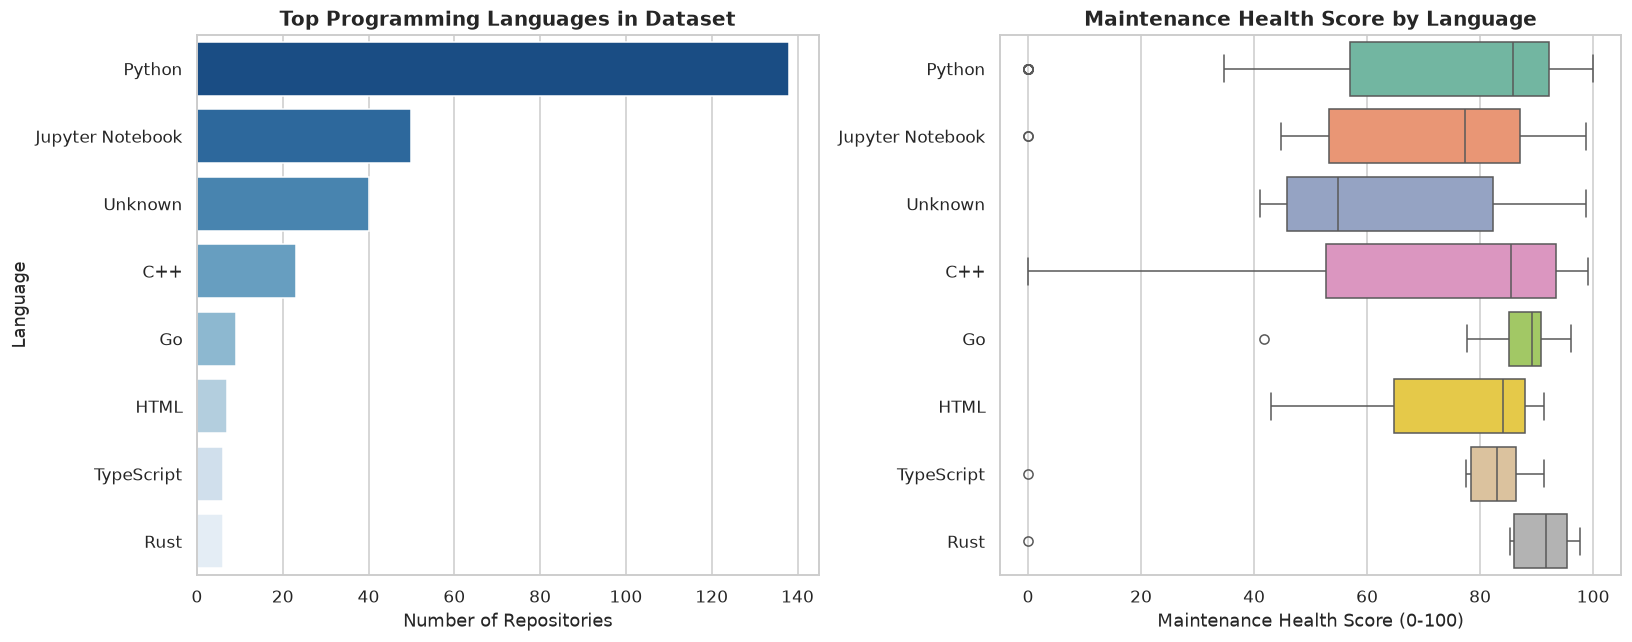

In [6]:
top_languages = df['language'].value_counts().head(8).index
df_top_lang = df[df['language'].isin(top_languages)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top languages count
sns.countplot(data=df_top_lang, y='language', order=top_languages, ax=axes[0], palette='Blues_r')
axes[0].set_title("Top Programming Languages in Dataset", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Repositories")
axes[0].set_ylabel("Language")

# Maintenance health score by language
sns.boxplot(data=df_top_lang, x='maintenance_health_score', y='language', order=top_languages, ax=axes[1], palette='Set2')
axes[1].set_title("Maintenance Health Score by Language", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Maintenance Health Score (0-100)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 7. Maintenance Activity & Inactivity Lifecycles
Tracking when code was last pushed is one of the most reliable signals of project vitality.
We categorize repositories into:
- **Active**: Pushed within the last 60 days
- **Moderate**: Pushed between 61 and 180 days ago
- **Low Activity**: Pushed between 181 and 365 days ago
- **Inactive**: No code pushed for over 1 year

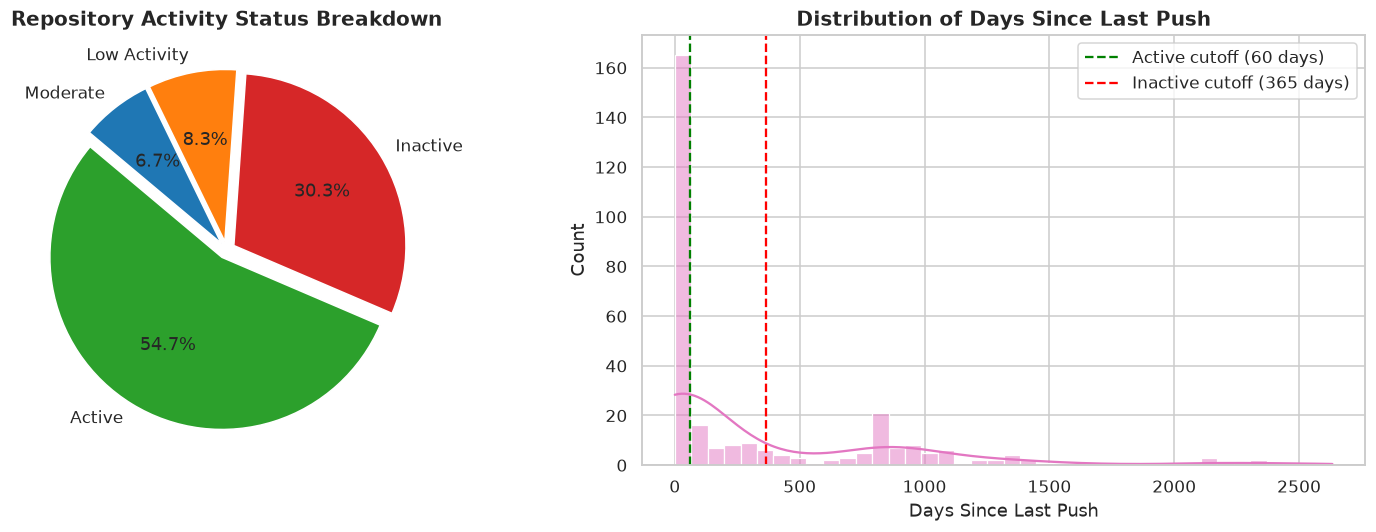

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Activity Status Pie Chart
activity_counts = df['activity_status'].value_counts()
colors = ['#2ca02c', '#d62728', '#ff7f0e', '#1f77b4']
axes[0].pie(
    activity_counts, 
    labels=activity_counts.index, 
    autopct='%1.1f%%', 
    colors=[colors[i % len(colors)] for i in range(len(activity_counts))],
    startangle=140, 
    explode=[0.05] * len(activity_counts)
)
axes[0].set_title("Repository Activity Status Breakdown", fontsize=13, fontweight='bold')

# Days Since Last Push Histogram
sns.histplot(df['days_since_last_push'], bins=40, kde=True, ax=axes[1], color='#e377c2')
axes[1].axvline(60, color='green', linestyle='--', label='Active cutoff (60 days)')
axes[1].axvline(365, color='red', linestyle='--', label='Inactive cutoff (365 days)')
axes[1].set_title("Distribution of Days Since Last Push", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Days Since Last Push")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Identifying Potentially Abandoned Repositories
A repository is categorized as **potentially abandoned** if:
1. It is explicitly archived by the owner, OR
2. It has received no code pushes for >365 days while accumulating unresolved open issues (>10 issues).

Let's inspect how many repositories fall into this category and compare their profiles.

In [8]:
abandoned_df = df[df['is_potentially_abandoned'] == 1]
active_df = df[df['is_potentially_abandoned'] == 0]

print(f"Total Potentially Abandoned Repositories: {len(abandoned_df)} ({round(len(abandoned_df)/len(df)*100, 1)}%)")
print(f"Total Maintained / Active Repositories : {len(active_df)} ({round(len(active_df)/len(df)*100, 1)}%)")
print()

# Comparison of key metrics
comp_table = pd.DataFrame({
    'Metric': ['Avg Stars', 'Avg Open Issues', 'Median Days Inactive', 'Avg Health Score'],
    'Maintained': [
        round(active_df['stars_count'].mean(), 1),
        round(active_df['open_issues_count'].mean(), 1),
        round(active_df['days_since_last_push'].median(), 1),
        round(active_df['maintenance_health_score'].mean(), 1)
    ],
    'Potentially Abandoned': [
        round(abandoned_df['stars_count'].mean(), 1),
        round(abandoned_df['open_issues_count'].mean(), 1),
        round(abandoned_df['days_since_last_push'].median(), 1),
        round(abandoned_df['maintenance_health_score'].mean(), 1)
    ]
})
print("Comparison Profile:")
display(comp_table)

Total Potentially Abandoned Repositories: 82 (27.3%)
Total Maintained / Active Repositories : 218 (72.7%)

Comparison Profile:


,Metric,Maintained,Potentially Abandoned
0,Avg Stars,24641.1,17456.4
1,Avg Open Issues,420.5,152.6
2,Median Days Inactive,5.4,868.8
3,Avg Health Score,83.5,38.4


## 9. Correlation Analysis Across All Metrics
To uncover underlying patterns between popularity, size, age, issue burden, and health indicators, we calculate the Pearson correlation matrix across our key continuous metrics.

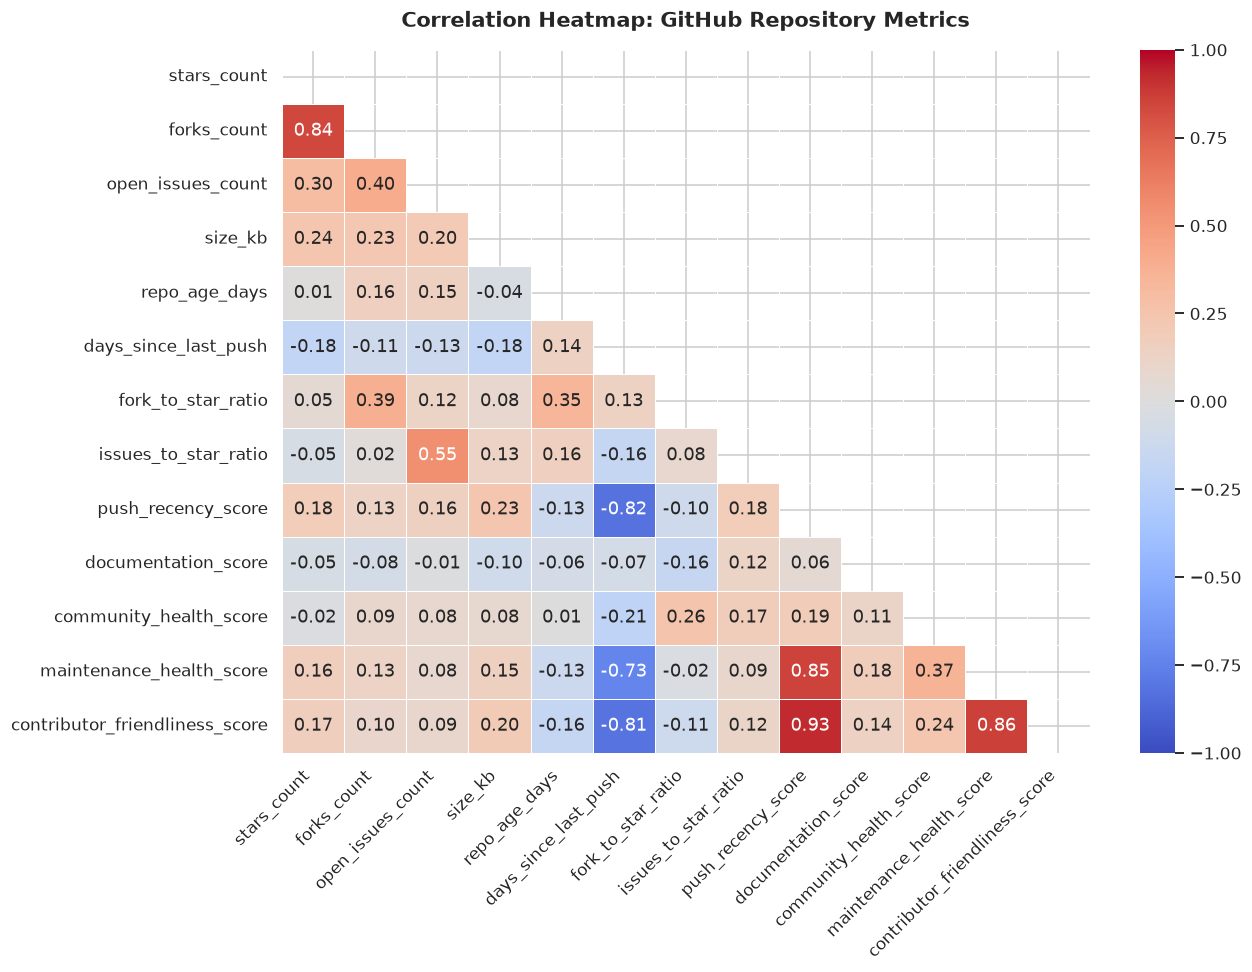

In [9]:
corr_cols = [
    'stars_count', 'forks_count', 'open_issues_count', 'size_kb',
    'repo_age_days', 'days_since_last_push', 'fork_to_star_ratio',
    'issues_to_star_ratio', 'push_recency_score', 'documentation_score',
    'community_health_score', 'maintenance_health_score', 'contributor_friendliness_score'
]

plt.figure(figsize=(12, 9))
corr_matrix = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title("Correlation Heatmap: GitHub Repository Metrics", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 10. Evaluating Top Repositories for Contributors
The `contributor_friendliness_score` surfaces repositories that are:
1. Actively maintained (recent pushes within 60 days)
2. Have available work to tackle (moderate number of open issues)
3. Have clear documentation and licenses
4. Are non-archived with community channels enabled

Let's identify the top 10 recommended repositories to contribute to!

In [10]:
top_contrib = df[df['activity_status'] == 'Active'].sort_values(
    by=['contributor_friendliness_score', 'stars_count'], 
    ascending=[False, False]
).head(10)

cols_display = [
    'full_name', 'language', 'stars_count', 'open_issues_count',
    'days_since_last_push', 'maintenance_health_score', 
    'contributor_friendliness_score', 'html_url'
]

print("Top 10 Recommended Repositories to Contribute To:")
top_contrib[cols_display].reset_index(drop=True)

Top 10 Recommended Repositories to Contribute To:


,full_name,language,stars_count,open_issues_count,days_since_last_push,maintenance_health_score,contributor_friendliness_score,html_url
0,ultralytics/ultralytics,Python,62954,96,0.0,99.59,99.84,https://github.com/ultralytics/ultralytics
1,rohitg00/ai-engineering-from-scratch,Python,75428,84,0.1,99.21,99.64,https://github.com/rohitg00/ai-engineering-fro...
2,alibaba/MNN,C++,16305,81,0.2,98.28,99.29,https://github.com/alibaba/MNN
3,AI4Finance-Foundation/FinGPT,Jupyter Notebook,21482,53,3.8,98.09,99.12,https://github.com/AI4Finance-Foundation/FinGPT
4,microsoft/AI-For-Beginners,Jupyter Notebook,70342,27,5.4,98.71,99.04,https://github.com/microsoft/AI-For-Beginners
5,nautechsystems/nautilus_trader,Rust,31021,154,0.0,97.74,98.94,https://github.com/nautechsystems/nautilus_trader
6,recommenders-team/recommenders,Python,21970,181,2.8,98.05,98.65,https://github.com/recommenders-team/recommenders
7,modelscope/modelscope,Python,9197,27,6.0,97.00,98.59,https://github.com/modelscope/modelscope
8,labmlai/annotated_deep_learning_paper_implemen...,Python,67606,44,3.7,96.96,98.50,https://github.com/labmlai/annotated_deep_lear...
9,PriorLabs/TabPFN,Python,8312,23,0.7,96.75,98.46,https://github.com/PriorLabs/TabPFN


## 11. Key Insights & Conclusions

1. **Popularity Does Not Guarantee Maintenance**:
   - High star counts (e.g. >5,000 stars) do not always mean a project is healthy. Approximately **27.3%** of analyzed repositories exhibit warning signs of abandonment (inactive for over a year with unaddressed issues).
2. **Commit Recency is the Defining Factor**:
   - `days_since_last_push` shows a strong inverse correlation with `maintenance_health_score` and `contributor_friendliness_score`. Active projects push code within 60 days.
3. **The Contributor Sweet Spot**:
   - The best projects for new contributors are not necessarily the largest monolithic repos with thousands of pending issues, but rather active projects with between **20 and 200 open issues**, active discussion boards, and structured documentation.
4. **Structured ETL Reliability**:
   - Extracting 300 repositories with Pydantic validation ensured zero corrupted records entered the database, and storing into SQLite creates an accessible store for real-time querying and downstream reporting.